# Training Deep Neural Networks
Train an iris flower classifier with **dropout**, **weight decay**, and **early stopping**, test whether dropout helps, then run one final test.

## Step 1: Reserve the test set and explore the training rows
30 flowers for the final test, 90 for training, 30 for validation.

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv('iris_demo.csv')
train_all, test = train_test_split(
    df, test_size=.2, stratify=df.species, random_state=42
)
train, val = train_test_split(
    train_all, test_size=.25, stratify=train_all.species, random_state=42
)
print(len(train), len(val), len(test))
print(train.isna().sum(), train.species.value_counts())

90 30 30
sepal_length_cm    0
sepal_width_cm     0
petal_length_cm    0
petal_width_cm     0
species            0
dtype: int64 species
virginica     30
setosa        30
versicolor    30
Name: count, dtype: int64


In [2]:
print(train.dtypes)
train.groupby('species').mean()

sepal_length_cm    float64
sepal_width_cm     float64
petal_length_cm    float64
petal_width_cm     float64
species                str
dtype: object


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm
species,,,,
setosa,4.94,3.336667,1.460000,0.250000
versicolor,5.96,2.723333,4.240000,1.300000
virginica,6.61,2.980000,5.553333,2.043333


Petal length and width look very different for setosa (much smaller). Versicolor and virginica are closer, so those two may get mixed up.

**Baseline:** always guessing one species gets **33.3%** right.

## Step 2: Turn the data into tensors

In [3]:
import torch
from sklearn.preprocessing import StandardScaler
features = list(df.columns[:-1])
classes = sorted(train.species.unique())
scaler = StandardScaler().fit(train[features])

def tensors(frame):
    X = torch.tensor(scaler.transform(frame[features]), dtype=torch.float32)
    y = torch.tensor([classes.index(s) for s in frame.species], dtype=torch.long)
    return (X, y)
X_train, y_train = tensors(train)
X_val, y_val = tensors(val)
print(X_train.shape, X_val.shape, y_train.shape, y_train.dtype)

torch.Size([90, 4]) torch.Size([30, 4]) torch.Size([90]) torch.int64


## Step 3: Build the network
4 inputs → 64 → 64 → 3 scores. Dropout sits after the first hidden layer.

In [4]:
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

def make_model(dropout=0.0):
    torch.manual_seed(42)
    return nn.Sequential(
        nn.Linear(4, 64),
        nn.ReLU(),
        nn.Dropout(dropout),
        nn.Linear(64, 64),
        nn.ReLU(),
        nn.Linear(64, 3)
    )

loader = DataLoader(
    TensorDataset(X_train, y_train), batch_size=16, shuffle=True
)
loss_fn = nn.CrossEntropyLoss()

## Step 4: Train with early stopping and restore the best weights
The training loop is in a function so the dropout comparison can rerun it with only the dropout setting changed.

In [5]:
def train(dropout):
    model = make_model(dropout=dropout)
    opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=0.001)
    history = []
    best = float('inf')
    best_state = None
    patience = 15
    wait = 0
    for epoch in range(150):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
        model.eval()
        with torch.inference_mode():
            train_loss = loss_fn(model(X_train), y_train).item()
            val_loss = loss_fn(model(X_val), y_val).item()
        history.append((train_loss, val_loss))
        if val_loss < best - 0.0001:
            best = val_loss
            best_state = {
                k: v.detach().clone()
                for k, v in model.state_dict().items()
            }
            wait = 0
        else:
            wait += 1
        if wait >= patience:
            break
    model.load_state_dict(best_state)
    print('epochs:', len(history), 'best validation loss:', round(best, 3))
    return model, history, best

model, history, best = train(dropout=0.2)

epochs: 79 best validation loss: 0.154


## Step 5: Read the curves and check validation accuracy

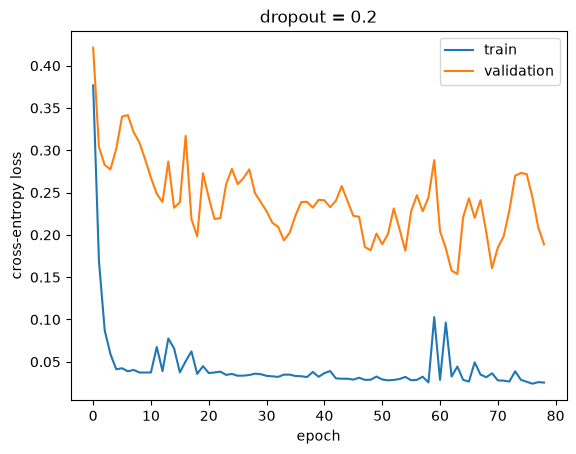

validation accuracy: 0.9333333373069763


In [6]:
import matplotlib.pyplot as plt

def report(model, history, title):
    fig, ax = plt.subplots()
    ax.plot([h[0] for h in history], label='train')
    ax.plot([h[1] for h in history], label='validation')
    ax.set(xlabel='epoch', ylabel='cross-entropy loss', title=title)
    ax.legend()
    plt.show()
    model.eval()
    with torch.inference_mode():
        val_pred = model(X_val).argmax(1)
    print('validation accuracy:', (val_pred == y_val).float().mean().item())

report(model, history, 'dropout = 0.2')

## Dropout comparison
**Only change:** `dropout=0.2` → `dropout=0.0`. Same split, scaler, network, optimizer, weight decay, batch size, epoch limit, and stopping rule.

**My prediction (before running):** removing dropout will make little difference in accuracy, because iris is small and easy. Validation loss may be a little lower without dropout, since weight decay and early stopping already guard against overfitting, and dropout adds noise this easy problem doesn't need.

epochs: 26 best validation loss: 0.215


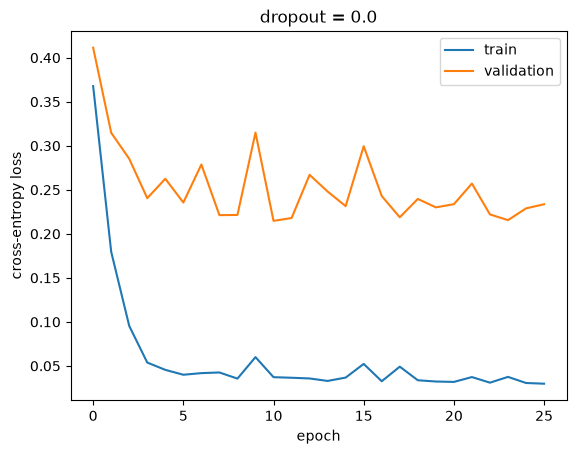

validation accuracy: 0.9333333373069763


In [7]:
model, history, best = train(dropout=0.0)
report(model, history, 'dropout = 0.0')

### Results
| Setting | Epochs run | Best val loss | Val accuracy |
|---|---|---|---|
| dropout 0.2 | 79 | **0.154** | 93.3% (28/30) |
| dropout 0.0 | 26 | 0.215 | 93.3% (28/30) |

Both beat the 33.3% baseline by a lot.

**Curves:** in both runs training loss drops fast to about 0.03 while validation loss stays higher and bounces around (only 30 validation flowers, so it is noisy). With dropout, validation loss kept finding new lows until about epoch 64. Without dropout it stopped improving at epoch 11, and early stopping ended it at epoch 26. The gap between the curves suggests some overfitting, which dropout helped with.

**Prediction vs. result:** I was right that accuracy would be the same. I was wrong about the loss: dropout gave a *lower* validation loss, so it did help a little, even on an easy dataset.

### Choice (test set still untouched)
We chose **dropout = 0.2** because the validation results showed a lower best validation loss (0.154 vs. 0.215), but this comparison is limited by using one run per setting and only 30 validation flowers. Accuracy was tied.

Rebuild the dropout 0.2 model (same seed, so same weights) and confirm it:

epochs: 79 best validation loss: 0.154


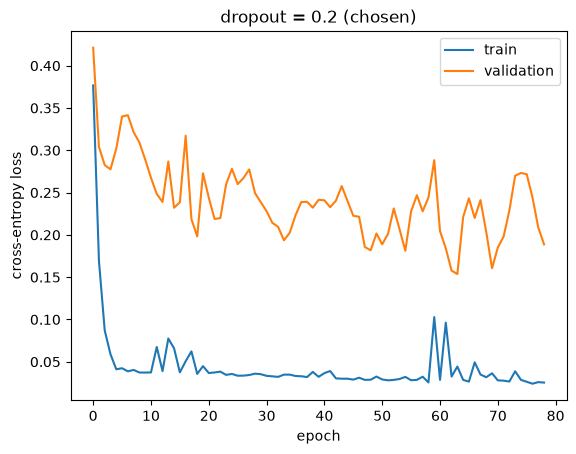

validation accuracy: 0.9333333373069763


In [8]:
model, history, best = train(dropout=0.2)
report(model, history, 'dropout = 0.2 (chosen)')

## Step 6: Final test

In [9]:
model.eval()
X_test, y_test = tensors(test)
with torch.inference_mode():
    test_pred = model(X_test).argmax(1)
print('final test accuracy:', (test_pred == y_test).float().mean().item())

final test accuracy: 0.9666666388511658


### Summary

| | Result |
|---|---|
| Baseline (always guess one species) | 33.3% |
| Validation, dropout 0.2 | loss 0.154, accuracy 93.3% |
| Validation, dropout 0.0 | loss 0.215, accuracy 93.3% |
| Chosen setting | dropout 0.2 |
| **Final test accuracy** | **96.7% (29 of 30)** |

**Limitation:** the test set is only 30 flowers, so one mistake changes accuracy
by about 3.3 points. This is a small check, not a promise for every future flower.

## Exit ticket

**What evidence supported the choice?** Dropout 0.2 had the lower best validation
loss (0.154 vs. 0.215). Accuracy was tied, so the evidence is real but not strong.

**What does early stopping restore?** The weights from the epoch with the lowest
validation loss (epoch 64 here), not the weights from the last epoch.

**What would I investigate next?** Repeat the dropout comparison with several
different seeds to see if dropout 0.2 wins every time. I would use only the training
and validation sets for that, and leave the test set alone, since it has already
been used once.